In [15]:
import os
import glob
import numpy as np
import pandas as pd
import rasterio
from rasterio.plot import show
import geopandas as gpd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable

BASE_DIR   = r"C:\Users\gerii\Documents\projects\tekeze"
CDI_BASE   = os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "CDI_future_lgbm")
SHP_PATH   = r"C:\Users\geri geri\Desktop\study_area\tekeze\tekeze.shp"
OUT_DIR    = os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "CDI_future_lgbm", "analysis_5year")
os.makedirs(OUT_DIR, exist_ok=True)

SCENARIOS   = ["ssp245", "ssp585"]
SCEN_LABELS = {"ssp245": "SSP2-4.5", "ssp585": "SSP5-8.5"}
SCEN_COLORS = {"ssp245": "#2166ac",  "ssp585": "#d7191c"}
YEARS_5     = [2030, 2035, 2040, 2045, 2050]
ALL_YEARS   = list(range(2030, 2051))

# drought classification consistent with previous scripts
CAT_COLORS  = ["#2ca25f", "#fee08b", "#fc8d59", "#d73027"]
CAT_LABELS  = ["No Drought",
               "Moderate",
               "Severe",
               "Extreme "]
cat_cmap    = ListedColormap(CAT_COLORS)
cat_norm    = BoundaryNorm([1, 2, 3, 4, 5], cat_cmap.N)

def classify(arr):
    cls = np.full(arr.shape, np.nan)
    cls[arr > -0.5]                          = 1
    cls[(arr <= -0.5) & (arr > -1.0)]        = 2
    cls[(arr <= -1.0) & (arr > -1.5)]        = 3
    cls[arr <= -1.5]                         = 4
    return cls

def load_raster(path):
    with rasterio.open(path) as src:
        arr     = src.read(1).astype(np.float32)
        profile = src.profile
        crs     = src.crs
        bounds  = src.bounds
        nd      = src.nodata
    if nd is not None:
        arr[arr == nd] = np.nan
    arr[arr <= -9999] = np.nan
    return arr, profile, crs, bounds

def annual_mean_map(scenario, year):
    folder  = os.path.join(CDI_BASE, scenario)
    pattern = os.path.join(folder, f"CDI_lgbm_{scenario}_{year}_*.tif")
    files   = sorted(glob.glob(pattern))
    if not files:
        return None, None, None, None
    stack, profile, crs, bounds = [], None, None, None
    for f in files:
        arr, profile, crs, bounds = load_raster(f)
        stack.append(arr)
    return np.nanmean(stack, axis=0), profile, crs, bounds

def basin_drought_pct(arr):
    valid = arr[~np.isnan(arr)]
    return float((valid < -0.5).mean() * 100) if len(valid) > 0 else np.nan

def mean_cdi(arr):
    valid = arr[~np.isnan(arr)]
    return float(np.nanmean(valid)) if len(valid) > 0 else np.nan

print("Loading shapefile ...")
shp = gpd.read_file(SHP_PATH)

print("Computing annual mean CDI maps ...")
annual_maps = {sc: {} for sc in SCENARIOS}
for sc in SCENARIOS:
    for yr in ALL_YEARS:
        arr, prof, crs, bnd = annual_mean_map(sc, yr)
        if arr is not None:
            annual_maps[sc][yr] = (arr, prof, crs, bnd)
            print(f"  {sc} {yr} -> mean CDI = {mean_cdi(arr):.3f}")
        else:
            print(f"  {sc} {yr} -> NO FILES FOUND")

# =============================================================================
# FIGURE 1: FIVE-YEAR PANEL MAP — CLASSIFIED CDI (2 rows x 5 cols)
# =============================================================================

print("\nGenerating classified 5-year panel map ...")

fig, axes = plt.subplots(2, 5, figsize=(28, 11),
                         gridspec_kw={"hspace": 0.3, "wspace": 0.150})
#fig.suptitle(
    #"Projected Annual Drought Classification — Five-Year Intervals (2030–2050)\n"
   ## fontsize=22,  y=1.01
#)

for row_idx, sc in enumerate(SCENARIOS):
    for col_idx, yr in enumerate(YEARS_5):
        ax = axes[row_idx, col_idx]

        if yr not in annual_maps[sc]:
            ax.set_visible(False)
            continue

        arr, prof, crs, bnd = annual_maps[sc][yr]
        cls_arr = classify(arr)

        epsg     = crs.to_epsg()
        shp_plot = shp.to_crs(epsg if epsg else crs.to_wkt())

        with rasterio.open(
            os.path.join(CDI_BASE, sc,
                         f"CDI_lgbm_{sc}_{yr}_01.tif")
        ) as src:
            transform = src.transform

        show(cls_arr, ax=ax, cmap=cat_cmap, norm=cat_norm,
             transform=transform)

        shp_plot.boundary.plot(ax=ax, edgecolor="black",
                               linewidth=1.5, zorder=5)

        ax.set_title(f"{SCEN_LABELS[sc]} — {yr}",
                     fontsize=25, pad=4)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

        valid   = arr[~np.isnan(arr)]
        pct_dry = (valid < -0.5).mean() * 100 if len(valid) > 0 else 0
        ax.set_xlabel(f"Mean CDI={mean_cdi(arr):.2f}" ,
              fontsize=23, labelpad=6)
#|  Drought={pct_dry:.1f}%"
legend_patches = [
    mpatches.Patch(facecolor=c, edgecolor="grey", label=l)
    for c, l in zip(CAT_COLORS, CAT_LABELS)
]
fig.legend(handles=legend_patches, loc="lower center", ncol=4,
           fontsize=25, framealpha=0.9,
           bbox_to_anchor=(0.46, -0.04))
           #title="Drought Category", title_fontsize=11)

panel_path = os.path.join(OUT_DIR, "CDI_5year_classified_panel.png")
fig.savefig(panel_path, dpi=450, bbox_inches="tight")
plt.close(fig)
print(f"  Saved: {panel_path}")

# =============================================================================
# FIGURE 2: ANNUAL MEAN CDI LINE PLOT 2030–2050
# =============================================================================

print("\nGenerating annual CDI line plot ...")

fig, ax = plt.subplots(figsize=(16, 6))

for sc in SCENARIOS:
    years_avail = sorted(annual_maps[sc].keys())
    cdi_vals    = [mean_cdi(annual_maps[sc][yr][0]) for yr in years_avail]
    ax.plot(years_avail, cdi_vals,
            color=SCEN_COLORS[sc], linewidth=2.5,
            marker="o", markersize=5, label=SCEN_LABELS[sc])
    ax.fill_between(years_avail,
                    [min(v, -0.5) for v in cdi_vals], -0.5,
                    where=[v < -0.5 for v in cdi_vals],
                    color=SCEN_COLORS[sc], alpha=0.12)

ax.axhline(0,    color="black",   linewidth=1.2, linestyle="--", alpha=0.5)
ax.axhline(-0.5, color="#fee08b", linewidth=1.2, linestyle=":",
           label="Moderate drought (−0.5)")
ax.axhline(-1.0, color="#fc8d59", linewidth=1.2, linestyle=":",
           label="Severe drought (−1.0)")
ax.axhline(-1.5, color="#d73027", linewidth=1.2, linestyle=":",
           label="Extreme drought (−1.5)")

for yr in YEARS_5:
    ax.axvline(yr, color="grey", linewidth=0.8, linestyle="--", alpha=0.4)

ax.set_xticks(ALL_YEARS)
ax.set_xticklabels([str(y) for y in ALL_YEARS], rotation=45, ha="right")
ax.tick_params(axis="x", labelsize=20)
ax.tick_params(axis="y", labelsize=20)
ax.set_xlabel("Year", fontsize=27)
ax.set_ylabel("Basin-Mean CDI", fontsize=27)
#ax.set_title(
    #"Projected Annual Mean CDI — Tekeze Basin (2030–2050)",
    #fontsize=14, fontweight="bold"
#)
ax.legend(fontsize=22, loc="lower left", framealpha=0.88)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

line_path = os.path.join(OUT_DIR, "CDI_annual_lineplot_2030_2050.png")
fig.savefig(line_path, dpi=450, bbox_inches="tight")
plt.close(fig)
print(f"  Saved: {line_path}")

# =============================================================================
# TABLE: DROUGHT AREA PERCENTAGE EVERY 5 YEARS
# =============================================================================

print("\nComputing drought area table ...")

table_rows = []
for yr in YEARS_5:
    row = {"Year": yr}
    for sc in SCENARIOS:
        if yr in annual_maps[sc]:
            row[SCEN_LABELS[sc]] = round(basin_drought_pct(annual_maps[sc][yr][0]), 2)
        else:
            row[SCEN_LABELS[sc]] = np.nan
    table_rows.append(row)

df_table = pd.DataFrame(table_rows)
df_table.columns = ["Year",
                    "SSP2-4.5 Drought Area (%)",
                    "SSP5-8.5 Drought Area (%)"]

csv_path = os.path.join(OUT_DIR, "drought_area_pct_5year.csv")
df_table.to_csv(csv_path, index=False)
print("\n" + df_table.to_string(index=False))
print(f"\n  Saved: {csv_path}")

print("\n" + "=" * 70)
print(f"  Panel map : {panel_path}")
print(f"  Line plot : {line_path}")
print(f"  Table CSV : {csv_path}")
print("Finished Successfully.")

Loading shapefile ...
Computing annual mean CDI maps ...
  ssp245 2030 -> mean CDI = -0.683
  ssp245 2031 -> mean CDI = -0.591
  ssp245 2032 -> mean CDI = -0.595
  ssp245 2033 -> mean CDI = -0.593
  ssp245 2034 -> mean CDI = -0.652
  ssp245 2035 -> mean CDI = -0.606
  ssp245 2036 -> mean CDI = -0.615
  ssp245 2037 -> mean CDI = -0.574
  ssp245 2038 -> mean CDI = -0.557
  ssp245 2039 -> mean CDI = -0.596
  ssp245 2040 -> mean CDI = -0.572
  ssp245 2041 -> mean CDI = -0.477
  ssp245 2042 -> mean CDI = -0.594
  ssp245 2043 -> mean CDI = -0.560
  ssp245 2044 -> mean CDI = -0.730
  ssp245 2045 -> mean CDI = -0.741
  ssp245 2046 -> mean CDI = -0.601
  ssp245 2047 -> mean CDI = -0.593
  ssp245 2048 -> mean CDI = -0.547
  ssp245 2049 -> mean CDI = -0.572
  ssp245 2050 -> mean CDI = -0.585
  ssp585 2030 -> mean CDI = -0.560
  ssp585 2031 -> mean CDI = -0.475
  ssp585 2032 -> mean CDI = -0.565
  ssp585 2033 -> mean CDI = -0.684
  ssp585 2034 -> mean CDI = -0.682
  ssp585 2035 -> mean CDI = -0.53

## Seasonal future cdi categories

Computing seasonal mean CDI maps (2030–2050) ...

  ssp245 | Bega (Oct–Jan) ...
  ssp245 -> mean CDI=-1.060  drought%=100.0%  n_months=84

  ssp245 | Belg (Feb–May) ...
  ssp245 -> mean CDI=-2.137  drought%=100.0%  n_months=84

  ssp245 | Kiremt (Jun–Sep) ...
  ssp245 -> mean CDI=1.392  drought%=0.0%  n_months=84

  ssp585 | Bega (Oct–Jan) ...
  ssp585 -> mean CDI=-0.982  drought%=100.0%  n_months=84

  ssp585 | Belg (Feb–May) ...
  ssp585 -> mean CDI=-2.150  drought%=100.0%  n_months=84

  ssp585 | Kiremt (Jun–Sep) ...
  ssp585 -> mean CDI=1.445  drought%=0.0%  n_months=84

Generating seasonal CDI panel map ...


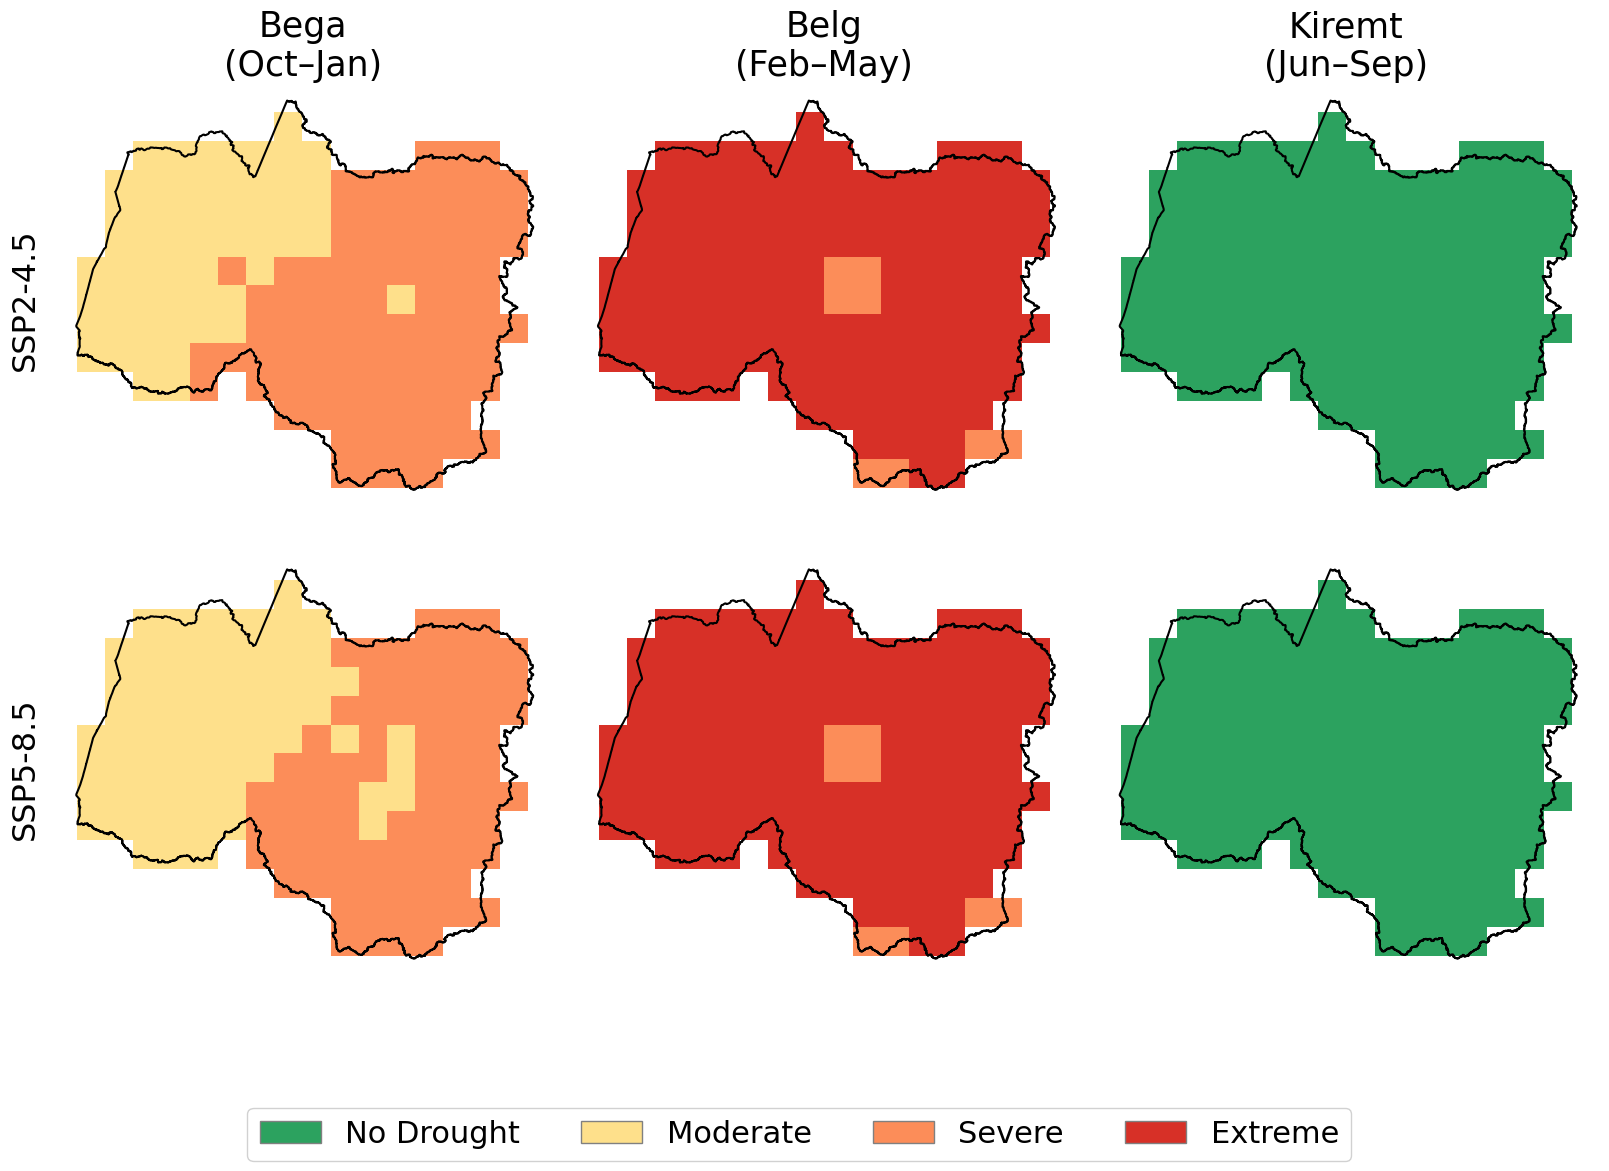


Saved : C:\Users\gerii\Documents\projects\tekeze\NEX-GDDP-CMIP6\CDI_future_lgbm\seasonal_analysis\CDI_seasonal_3season_classification_2030_2050.png
Size  : 7242 x 5268 px
File  : 992 KB
Finished Successfully.


In [11]:
import os
import glob
import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
from rasterio.plot import show
import warnings
warnings.filterwarnings("ignore")

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze\NEX-GDDP-CMIP6\CDI_future_lgbm"
SHP_PATH = r"C:\Users\geri geri\Desktop\study_area\tekeze\tekeze.shp"
OUT_DIR  = os.path.join(BASE_DIR, "seasonal_analysis")
os.makedirs(OUT_DIR, exist_ok=True)

SCENARIOS   = ["ssp245", "ssp585"]
SCEN_LABELS = {"ssp245": "SSP2-4.5", "ssp585": "SSP5-8.5"}

# three seasons commonly used in East Africa / Ethiopia literature
SEASONS = {
    "Bega\n(Oct–Jan)":  [10, 11, 12, 1],
    "Belg\n(Feb–May)":  [2,  3,  4,  5],
    "Kiremt\n(Jun–Sep)": [6,  7,  8,  9],
}

CAT_COLORS = ["#2ca25f", "#fee08b", "#fc8d59", "#d73027"]
CAT_LABELS = ["No Drought",
              "Moderate",
              "Severe",
              "Extreme"]
cat_cmap   = ListedColormap(CAT_COLORS)
cat_norm   = BoundaryNorm([1, 2, 3, 4, 5], cat_cmap.N)

shp = gpd.read_file(SHP_PATH)
if not shp.crs.is_geographic:
    shp = shp.to_crs(epsg=4326)

def classify(arr):
    cls = np.full(arr.shape, np.nan)
    cls[arr >   0.0]                   = 1
    cls[(arr <=  0.0) & (arr > -1.0)]  = 2
    cls[(arr <= -1.0) & (arr > -2.0)]  = 3
    cls[arr <= -2.0]                   = 4
    return cls

def load_raster(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype(np.float32)
        nd  = src.nodata
        if nd is not None: arr[arr == nd] = np.nan
        arr[arr <= -9999] = np.nan
        transform = src.transform
        crs       = src.crs
    return arr, transform, crs

def seasonal_mean_classify(scenario, season_months):
    folder         = os.path.join(BASE_DIR, scenario)
    stack          = []
    transform, crs = None, None

    for yr in range(2030, 2051):
        for mm in season_months:
            fname = f"CDI_lgbm_{scenario}_{yr}_{mm:02d}.tif"
            fpath = os.path.join(folder, fname)
            if not os.path.exists(fpath):
                continue
            arr, tf, cr = load_raster(fpath)
            stack.append(arr)
            if transform is None:
                transform = tf
                crs       = cr

    if not stack:
        print(f"  NO FILES: {scenario}")
        return None, None, None

    mean_arr = np.nanmean(np.stack(stack, axis=0), axis=0)
    cls_arr  = classify(mean_arr)

    valid   = cls_arr[~np.isnan(cls_arr)]
    pct_dry = (valid >= 2).mean() * 100
    print(f"  {scenario} -> "
          f"mean CDI={np.nanmean(mean_arr):.3f}  "
          f"drought%={pct_dry:.1f}%  "
          f"n_months={len(stack)}")
    return cls_arr, transform, crs

# =============================================================================
# LOAD
# =============================================================================

print("Computing seasonal mean CDI maps (2030–2050) ...")
data = {}
for sc in SCENARIOS:
    data[sc] = {}
    for season, months in SEASONS.items():
        print(f"\n  {sc} | {season.replace(chr(10),' ')} ...")
        cls_arr, transform, crs = seasonal_mean_classify(sc, months)
        data[sc][season] = (cls_arr, transform, crs)

# =============================================================================
# FIGURE: 2 rows x 3 cols
# =============================================================================

print("\nGenerating seasonal CDI panel map ...")

fig, axes = plt.subplots(
    2, 3,
    figsize=(20, 12),
    gridspec_kw={"hspace": 0.03, "wspace": 0.03}
)

#fig.suptitle(
    #"Projected Seasonal CDI Classification — Tekeze Basin (2030–2050)\n"
    #"SSP2-4.5 (top row)  |  SSP5-8.5 (bottom row)",
   # fontsize=22, y=1.01, fontweight="normal"
#)

for row_idx, sc in enumerate(SCENARIOS):
    for col_idx, season in enumerate(SEASONS.keys()):
        ax = axes[row_idx, col_idx]

        cls_arr, transform, crs = data[sc][season]

        if cls_arr is None:
            ax.set_facecolor("#eeeeee")
            ax.text(0.5, 0.5, "No Data",
                    ha="center", va="center",
                    transform=ax.transAxes)
            continue

        show(cls_arr, ax=ax, cmap=cat_cmap,
             norm=cat_norm, transform=transform)

        try:
            epsg     = crs.to_epsg()
            shp_plot = shp.to_crs(epsg if epsg else crs.to_wkt())
            shp_plot.boundary.plot(ax=ax, edgecolor="black",
                                   linewidth=1.5, zorder=5)
        except Exception:
            pass

        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

        if row_idx == 0:
            ax.set_title(season, fontsize=25,
                          pad=4)

        if col_idx == 0:
            ax.set_ylabel(SCEN_LABELS[sc], fontsize=23,
                          labelpad=6)

legend_patches = [
    mpatches.Patch(facecolor=c, edgecolor="grey", label=l)
    for c, l in zip(CAT_COLORS, CAT_LABELS)
]

fig.legend(handles=legend_patches,
           loc="lower center", ncol=4,
           fontsize=22, framealpha=0.9,
           bbox_to_anchor=(0.5, -0.04))

out_path = os.path.join(OUT_DIR,
           "CDI_seasonal_3season_classification_2030_2050.png")
fig.savefig(out_path, dpi=450, bbox_inches="tight")
plt.show()
plt.close(fig)

from PIL import Image
img = Image.open(out_path)
print(f"\nSaved : {out_path}")
print(f"Size  : {img.size[0]} x {img.size[1]} px")
print(f"File  : {round(os.path.getsize(out_path)/1024)} KB")
print("Finished Successfully.")

## seasonal future climate

In [7]:
# =============================================================================
# DIAGNOSTIC: CHECK INPUT PR/TA DISTRIBUTION BY SEASON FOR FUTURE PERIOD
# =============================================================================

import os
import numpy as np
import rasterio

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze"
PR_DIR = os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "pr_corrected_RF", "GFDL-CM4")
TA_DIR = os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "ta_corrected_RF", "INM-CM5-0")

SEASONS = {
    "Bega (Oct-Jan)":   [10, 11, 12, 1],
    "Belg (Feb-May)":   [2, 3, 4, 5],
    "Kiremt (Jun-Sep)": [6, 7, 8, 9],
}

for scenario in ["ssp245", "ssp585"]:
    print(f"\n{'='*60}\nSCENARIO: {scenario}\n{'='*60}")

    for season, months in SEASONS.items():
        pr_vals = []
        ta_vals = []

        for year in range(2030, 2051):
            for month in months:
                pr_path = os.path.join(PR_DIR, scenario, f"{year}_{month:02d}.tif")
                ta_path = os.path.join(TA_DIR, scenario, f"{year}_{month:02d}.tif")

                if os.path.exists(pr_path):
                    with rasterio.open(pr_path) as src:
                        arr = src.read(1)
                        nd = src.nodata
                        arr = arr[arr != nd] if nd is not None else arr.flatten()
                        arr = arr[arr > -9999]
                        pr_vals.extend(arr.tolist())

                if os.path.exists(ta_path):
                    with rasterio.open(ta_path) as src:
                        arr = src.read(1)
                        nd = src.nodata
                        arr = arr[arr != nd] if nd is not None else arr.flatten()
                        arr = arr[arr > -9999]
                        ta_vals.extend(arr.tolist())

        pr_vals = np.array(pr_vals)
        ta_vals = np.array(ta_vals)

        print(f"\n  {season}:")
        print(f"    PR  mean={np.nanmean(pr_vals):.2f}  min={np.nanmin(pr_vals):.2f}  "
              f"max={np.nanmax(pr_vals):.2f}  n={len(pr_vals)}")
        print(f"    TA  mean={np.nanmean(ta_vals):.2f}  min={np.nanmin(ta_vals):.2f}  "
              f"max={np.nanmax(ta_vals):.2f}  n={len(ta_vals)}")


SCENARIO: ssp245

  Bega (Oct-Jan):
    PR  mean=18.11  min=0.13  max=305.01  n=10944
    TA  mean=21.55  min=13.38  max=32.60  n=14364

  Belg (Feb-May):
    PR  mean=38.86  min=0.20  max=299.84  n=11628
    TA  mean=23.26  min=14.07  max=32.82  n=14364

  Kiremt (Jun-Sep):
    PR  mean=180.55  min=7.77  max=400.32  n=11628
    TA  mean=21.58  min=15.23  max=32.63  n=14364

SCENARIO: ssp585

  Bega (Oct-Jan):
    PR  mean=24.31  min=0.13  max=282.57  n=2565
    TA  mean=21.69  min=13.49  max=32.59  n=14364

  Belg (Feb-May):
    PR  mean=26.66  min=0.22  max=172.77  n=2394
    TA  mean=23.48  min=14.63  max=32.82  n=14364

  Kiremt (Jun-Sep):
    PR  mean=199.85  min=9.65  max=401.20  n=2736
    TA  mean=21.69  min=15.09  max=32.75  n=14364


# imapcts of climate trend on CDI 

In [1]:
# =============================================================================
# TREND ANALYSIS — FUTURE PR & TA (2030–2050)
# SSP245 vs SSP585 | GFDL-CM4 (PR) | INM-CM5-0 (TA)
# =============================================================================

import os
import glob
import numpy as np
import pandas as pd
import rasterio
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze"
PR_DIR   = os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "pr_corrected", "GFDL-CM4")
TA_DIR   = os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "ta_corrected", "INM-CM5-0")
OUT_DIR  = os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "CDI_future_lgbm", "analysis_5year")
os.makedirs(OUT_DIR, exist_ok=True)

SCENARIOS   = ["ssp245", "ssp585"]
SCEN_LABELS = {"ssp245": "SSP2-4.5", "ssp585": "SSP5-8.5"}
SCEN_COLORS = {"ssp245": "#2166ac",  "ssp585": "#d7191c"}
ALL_YEARS   = list(range(2030, 2051))

# =============================================================================
# HELPER
# =============================================================================

def load_raster(path):
    with rasterio.open(path) as src:
        arr  = src.read(1).astype(np.float32)
        nd   = src.nodata
    if nd is not None:
        arr[arr == nd] = np.nan
    arr[arr <= -9999] = np.nan
    return arr

def annual_mean_variable(var_dir, scenario, year):
    folder  = os.path.join(var_dir, scenario)
    pattern = os.path.join(folder, f"{year}_*.tif")
    files   = sorted(glob.glob(pattern))
    if not files:
        return np.nan
    stack = []
    for f in files:
        arr = load_raster(f)
        stack.append(np.nanmean(arr))
    return float(np.nanmean(stack))

# =============================================================================
# EXTRACT ANNUAL MEAN PR AND TA FOR BOTH SCENARIOS
# =============================================================================

print("Extracting annual mean PR and TA ...")

records = []
for sc in SCENARIOS:
    for yr in ALL_YEARS:
        pr_mean = annual_mean_variable(PR_DIR, sc, yr)
        ta_mean = annual_mean_variable(TA_DIR, sc, yr)
        records.append({
            "Scenario": sc,
            "Year":     yr,
            "PR_mean":  pr_mean,
            "TA_mean":  ta_mean,
        })
        print(f"  {sc} {yr} -> PR={pr_mean:.2f}  TA={ta_mean:.2f}")

df = pd.DataFrame(records)
df.to_csv(os.path.join(OUT_DIR, "pr_ta_annual_trend.csv"), index=False)

# =============================================================================
# TREND (Sen's slope + Mann-Kendall via scipy)
# =============================================================================

print("\nTrend Statistics (Linear regression as proxy for Sen slope):")

trend_rows = []
for sc in SCENARIOS:
    sub = df[df["Scenario"] == sc].sort_values("Year")

    pr_slope, pr_int, pr_r, pr_p, _ = stats.linregress(sub["Year"], sub["PR_mean"])
    ta_slope, ta_int, ta_r, ta_p, _ = stats.linregress(sub["Year"], sub["TA_mean"])

    trend_rows.append({
        "Scenario":     SCEN_LABELS[sc],
        "PR_slope":     round(pr_slope, 4),
        "PR_r2":        round(pr_r**2,  3),
        "PR_pvalue":    round(pr_p,     4),
        "TA_slope":     round(ta_slope, 4),
        "TA_r2":        round(ta_r**2,  3),
        "TA_pvalue":    round(ta_p,     4),
    })

    print(f"\n  {SCEN_LABELS[sc]}:")
    print(f"    PR -> slope={pr_slope:.4f} mm/yr  p={pr_p:.4f}")
    print(f"    TA -> slope={ta_slope:.4f} °C/yr  p={ta_p:.4f}")

df_trend = pd.DataFrame(trend_rows)
df_trend.to_csv(os.path.join(OUT_DIR, "pr_ta_trend_stats.csv"), index=False)
print("\n" + df_trend.to_string(index=False))

# =============================================================================
# FIGURE: 2x2 PANEL — PR trend (top) | TA trend (bottom)
#         left = SSP245 | right = SSP585
# =============================================================================

print("\nGenerating PR & TA trend figure ...")

fig, axes = plt.subplots(2, 2, figsize=(18, 10),
                         gridspec_kw={"hspace": 0.38, "wspace": 0.28})

var_info = [
    ("PR_mean", "Annual Mean Precipitation (mm)", "PR"),
    ("TA_mean", "Annual Mean Temperature (°C)",   "TA"),
]

for row_idx, (col, ylabel, vname) in enumerate(var_info):
    for col_idx, sc in enumerate(SCENARIOS):
        ax  = axes[row_idx, col_idx]
        sub = df[df["Scenario"] == sc].sort_values("Year")
        x   = sub["Year"].values
        y   = sub[col].values

        slope, intercept, r, p, _ = stats.linregress(x, y)
        trend_line = slope * x + intercept
        sig        = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"

        ax.plot(x, y, color=SCEN_COLORS[sc],
                linewidth=2.2, marker="o", markersize=4,
                label=SCEN_LABELS[sc])
        ax.plot(x, trend_line, color="black",
                linewidth=1.8, linestyle="--",
                label=f"Trend: {slope:+.3f}/yr")

        ax.fill_between(x, y, trend_line,
                        alpha=0.10, color=SCEN_COLORS[sc])

        ax.set_xticks(ALL_YEARS[::2])
        ax.set_xticklabels([str(y) for y in ALL_YEARS[::2]],
                           rotation=45, ha="right", fontsize=10)
        ax.set_ylabel(ylabel, fontsize=12)
        ax.set_xlabel("Year", fontsize=12)
        ax.set_title(f"{SCEN_LABELS[sc]} — {vname} Trend",
                     fontsize=13, fontweight="bold")

        ax.text(0.03, 0.95,
                f"Slope = {slope:+.4f}/yr\n"
                f"R² = {r**2:.3f}\n"
                f"p = {p:.4f} ({sig})",
                transform=ax.transAxes, fontsize=11,
                verticalalignment="top",
                bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                          edgecolor="grey", alpha=0.85))

        ax.legend(fontsize=10, loc="upper right", framealpha=0.85)
        ax.grid(True, linestyle="--", alpha=0.4)

fig.suptitle(
    "Projected Precipitation and Temperature Trends (2030–2050)\n"
    "GFDL-CM4 (PR) | INM-CM5-0 (TA)",
    fontsize=15, fontweight="bold"
)

trend_fig_path = os.path.join(OUT_DIR, "PR_TA_trend_2030_2050.png")
fig.savefig(trend_fig_path, dpi=300, bbox_inches="tight")
plt.close(fig)
print(f"  Saved: {trend_fig_path}")

# =============================================================================
# FIGURE 2: COMBINED — PR and TA on same x-axis per scenario (twin axis)
# =============================================================================

print("\nGenerating combined twin-axis trend figure ...")

fig, axes = plt.subplots(1, 2, figsize=(18, 6),
                         gridspec_kw={"wspace": 0.32})

for col_idx, sc in enumerate(SCENARIOS):
    ax1 = axes[col_idx]
    ax2 = ax1.twinx()

    sub = df[df["Scenario"] == sc].sort_values("Year")
    x   = sub["Year"].values

    pr_slope, pr_int, _, pr_p, _ = stats.linregress(x, sub["PR_mean"].values)
    ta_slope, ta_int, _, ta_p, _ = stats.linregress(x, sub["TA_mean"].values)

    # PR on left axis
    l1, = ax1.plot(x, sub["PR_mean"], color="#2166ac",
                   linewidth=2.2, marker="o", markersize=4,
                   label="Precipitation (mm)")
    ax1.plot(x, pr_slope * x + pr_int, color="#2166ac",
             linewidth=1.5, linestyle="--")

    # TA on right axis
    l2, = ax2.plot(x, sub["TA_mean"], color="#d7191c",
                   linewidth=2.2, marker="s", markersize=4,
                   label="Temperature (°C)")
    ax2.plot(x, ta_slope * x + ta_int, color="#d7191c",
             linewidth=1.5, linestyle="--")

    ax1.set_xlabel("Year", fontsize=12)
    ax1.set_ylabel("Precipitation (mm)", fontsize=12, color="#2166ac")
    ax2.set_ylabel("Temperature (°C)",   fontsize=12, color="#d7191c")
    ax1.tick_params(axis="y", labelcolor="#2166ac")
    ax2.tick_params(axis="y", labelcolor="#d7191c")
    ax1.set_xticks(ALL_YEARS[::2])
    ax1.set_xticklabels([str(y) for y in ALL_YEARS[::2]],
                        rotation=45, ha="right", fontsize=10)

    ax1.set_title(f"{SCEN_LABELS[sc]} — PR & TA Trend (2030–2050)",
                  fontsize=13, fontweight="bold")

    stats_txt = (
        f"PR slope = {pr_slope:+.3f} mm/yr  (p={pr_p:.3f})\n"
        f"TA slope = {ta_slope:+.3f} °C/yr  (p={ta_p:.3f})"
    )
    ax1.text(0.03, 0.97, stats_txt, transform=ax1.transAxes,
             fontsize=10, verticalalignment="top",
             bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                       edgecolor="grey", alpha=0.85))

    lines  = [l1, l2]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, fontsize=10, loc="upper right", framealpha=0.85)
    ax1.grid(True, linestyle="--", alpha=0.4)

fig.suptitle(
    "Projected Precipitation and Temperature Co-evolution (2030–2050)",
    fontsize=15, fontweight="bold"
)

combined_fig_path = os.path.join(OUT_DIR, "PR_TA_combined_twinaxis_2030_2050.png")
fig.savefig(combined_fig_path, dpi=300, bbox_inches="tight")
plt.close(fig)
print(f"  Saved: {combined_fig_path}")

print("\n" + "=" * 70)
print(f"  Trend CSV        : {os.path.join(OUT_DIR, 'pr_ta_annual_trend.csv')}")
print(f"  Trend stats CSV  : {os.path.join(OUT_DIR, 'pr_ta_trend_stats.csv')}")
print(f"  4-panel figure   : {trend_fig_path}")
print(f"  Twin-axis figure : {combined_fig_path}")
print("Finished Successfully.")

Extracting annual mean PR and TA ...
  ssp245 2030 -> PR=74.69  TA=21.80
  ssp245 2031 -> PR=90.36  TA=21.99
  ssp245 2032 -> PR=94.18  TA=21.69
  ssp245 2033 -> PR=91.75  TA=22.37
  ssp245 2034 -> PR=71.18  TA=22.05
  ssp245 2035 -> PR=81.01  TA=22.01
  ssp245 2036 -> PR=93.25  TA=21.31
  ssp245 2037 -> PR=81.90  TA=21.71
  ssp245 2038 -> PR=90.39  TA=22.80
  ssp245 2039 -> PR=95.04  TA=22.75
  ssp245 2040 -> PR=78.42  TA=22.61
  ssp245 2041 -> PR=120.35  TA=22.68
  ssp245 2042 -> PR=86.86  TA=22.11
  ssp245 2043 -> PR=85.99  TA=21.39
  ssp245 2044 -> PR=79.26  TA=21.82
  ssp245 2045 -> PR=57.08  TA=22.02
  ssp245 2046 -> PR=84.76  TA=21.83
  ssp245 2047 -> PR=80.19  TA=22.41
  ssp245 2048 -> PR=85.91  TA=21.97
  ssp245 2049 -> PR=94.55  TA=22.91
  ssp245 2050 -> PR=87.79  TA=22.11
  ssp585 2030 -> PR=90.64  TA=21.74
  ssp585 2031 -> PR=113.60  TA=21.80
  ssp585 2032 -> PR=91.68  TA=21.53
  ssp585 2033 -> PR=79.03  TA=22.77
  ssp585 2034 -> PR=75.88  TA=22.14
  ssp585 2035 -> PR=95.81